# Task 5: EDA and Machine Learning - CO2 Dataset

Only **pandas, numpy and matplotlib** are used. Linear and logistic regression are implemented from scratch with numpy.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

## 1. EDA

In [2]:
df = pd.read_csv('co2.csv')
df.head()

,Make,Model,Vehicle Class,Engine Size(L),Cylinders,Transmission,Fuel Type,Fuel Consumption City (L/100 km),Fuel Consumption Hwy (L/100 km),Fuel Consumption Comb (L/100 km),Fuel Consumption Comb (mpg),CO2 Emissions(g/km)
0,ACURA,ILX,COMPACT,2.0,4,AS5,Z,9.9,6.7,8.5,33,196
1,ACURA,ILX,COMPACT,2.4,4,M6,Z,11.2,7.7,9.6,29,221
2,ACURA,ILX HYBRID,COMPACT,1.5,4,AV7,Z,6.0,5.8,5.9,48,136
3,ACURA,MDX 4WD,SUV - SMALL,3.5,6,AS6,Z,12.7,9.1,11.1,25,255
4,ACURA,RDX AWD,SUV - SMALL,3.5,6,AS6,Z,12.1,8.7,10.6,27,244


In [3]:
df.shape

(7385, 12)

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7385 entries, 0 to 7384
Data columns (total 12 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   Make                              7385 non-null   str    
 1   Model                             7385 non-null   str    
 2   Vehicle Class                     7385 non-null   str    
 3   Engine Size(L)                    7385 non-null   float64
 4   Cylinders                         7385 non-null   int64  
 5   Transmission                      7385 non-null   str    
 6   Fuel Type                         7385 non-null   str    
 7   Fuel Consumption City (L/100 km)  7385 non-null   float64
 8   Fuel Consumption Hwy (L/100 km)   7385 non-null   float64
 9   Fuel Consumption Comb (L/100 km)  7385 non-null   float64
 10  Fuel Consumption Comb (mpg)       7385 non-null   int64  
 11  CO2 Emissions(g/km)               7385 non-null   int64  
dtypes: float64(4), in

In [5]:
df.describe()

,Engine Size(L),Cylinders,Fuel Consumption City (L/100 km),Fuel Consumption Hwy (L/100 km),Fuel Consumption Comb (L/100 km),Fuel Consumption Comb (mpg),CO2 Emissions(g/km)
count,7385.000000,7385.000000,7385.000000,7385.000000,7385.000000,7385.000000,7385.000000
mean,3.160068,5.615030,12.556534,9.041706,10.975071,27.481652,250.584699
std,1.354170,1.828307,3.500274,2.224456,2.892506,7.231879,58.512679
min,0.900000,3.000000,4.200000,4.000000,4.100000,11.000000,96.000000
25%,2.000000,4.000000,10.100000,7.500000,8.900000,22.000000,208.000000
50%,3.000000,6.000000,12.100000,8.700000,10.600000,27.000000,246.000000
75%,3.700000,6.000000,14.600000,10.200000,12.600000,32.000000,288.000000
max,8.400000,16.000000,30.600000,20.600000,26.100000,69.000000,522.000000


In [6]:
# checking null values and duplicates
print(df.isnull().sum())
print('Duplicates:', df.duplicated().sum())

Make                                0
Model                               0
Vehicle Class                       0
Engine Size(L)                      0
Cylinders                           0
Transmission                        0
Fuel Type                           0
Fuel Consumption City (L/100 km)    0
Fuel Consumption Hwy (L/100 km)     0
Fuel Consumption Comb (L/100 km)    0
Fuel Consumption Comb (mpg)         0
CO2 Emissions(g/km)                 0
dtype: int64
Duplicates: 1103


In [7]:
df = df.drop_duplicates().reset_index(drop=True)
df.shape

(6282, 12)

In [8]:
# renaming columns to make them easier to use
df.columns = ['make','model','vehicle_class','engine_size','cylinders','transmission','fuel_type',
              'fc_city','fc_hwy','fc_comb','mpg','co2']

In [9]:
df['vehicle_class'].value_counts()

vehicle_class
SUV - SMALL                 1006
MID-SIZE                     983
COMPACT                      903
SUV - STANDARD               613
SUBCOMPACT                   533
FULL-SIZE                    508
PICKUP TRUCK - STANDARD      475
TWO-SEATER                   381
MINICOMPACT                  274
STATION WAGON - SMALL        214
PICKUP TRUCK - SMALL         133
VAN - PASSENGER               66
SPECIAL PURPOSE VEHICLE       65
MINIVAN                       61
STATION WAGON - MID-SIZE      45
VAN - CARGO                   22
Name: count, dtype: int64

In [10]:
df['fuel_type'].value_counts()

fuel_type
X    3039
Z    2765
E     330
D     147
N       1
Name: count, dtype: int64

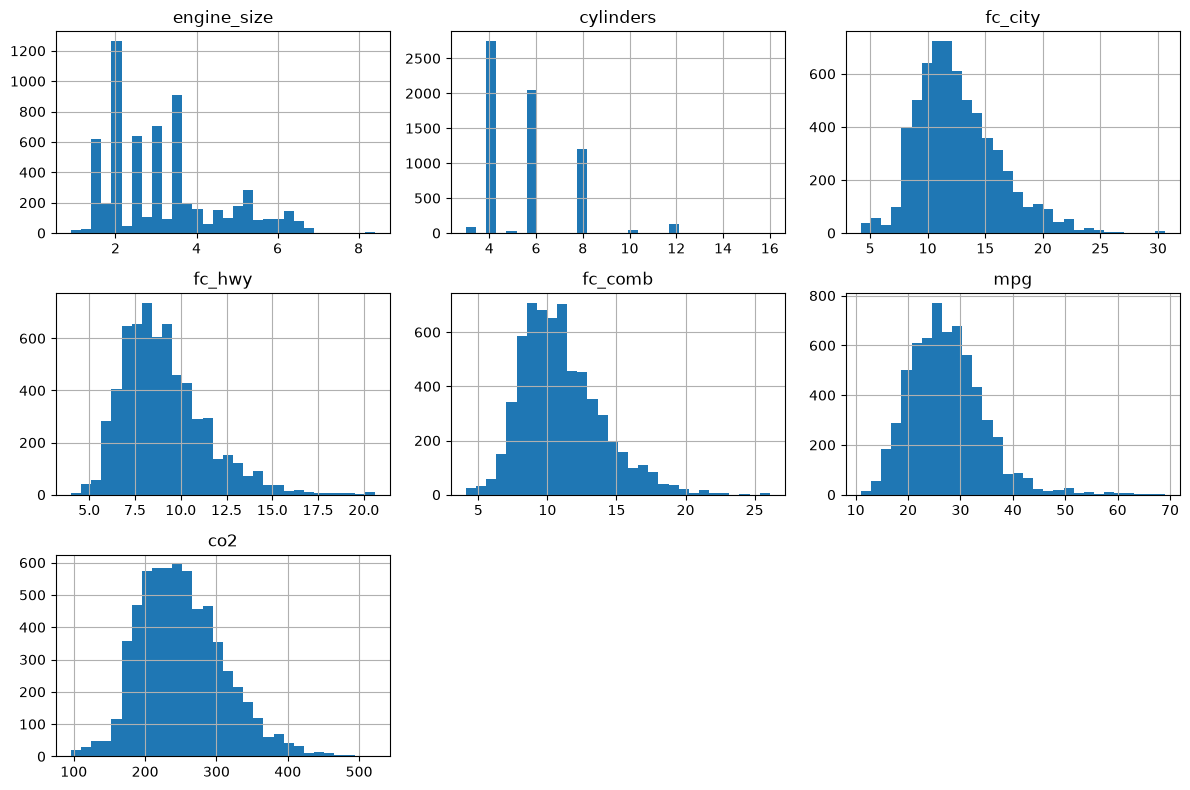

In [11]:
df.hist(figsize=(12,8), bins=30)
plt.tight_layout()
plt.show()

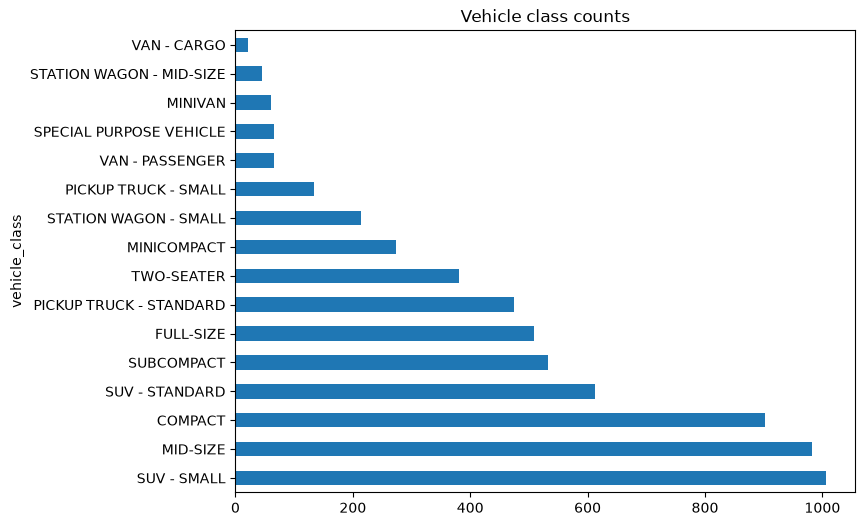

In [12]:
df['vehicle_class'].value_counts().plot(kind='barh', figsize=(8,6))
plt.title('Vehicle class counts')
plt.show()

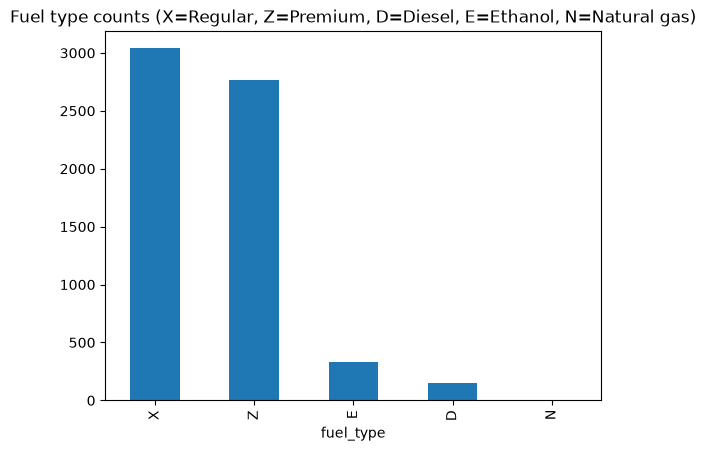

In [13]:
df['fuel_type'].value_counts().plot(kind='bar')
plt.title('Fuel type counts (X=Regular, Z=Premium, D=Diesel, E=Ethanol, N=Natural gas)')
plt.show()

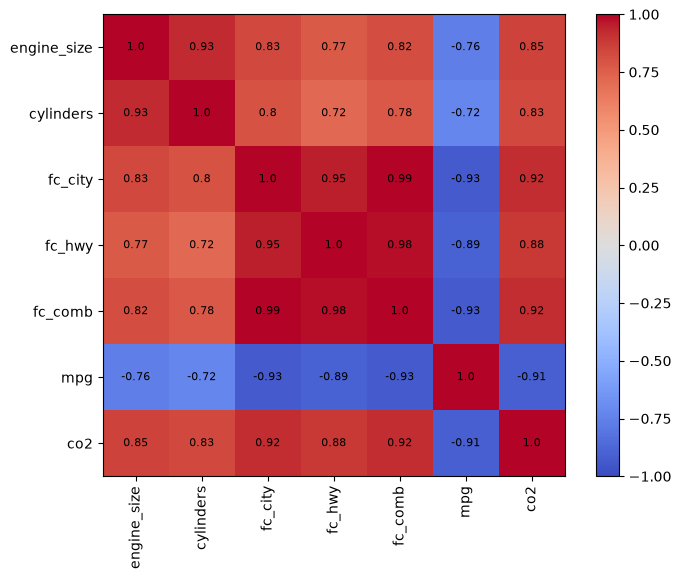

In [15]:
corr = df.corr(numeric_only=True)
plt.figure(figsize=(8,6))
plt.imshow(corr, cmap='coolwarm', vmin=-1, vmax=1)
plt.colorbar()
plt.xticks(range(len(corr)), corr.columns, rotation=90)
plt.yticks(range(len(corr)), corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        plt.text(j, i, round(corr.iloc[i, j], 2), ha='center', va='center', fontsize=8)
plt.show()

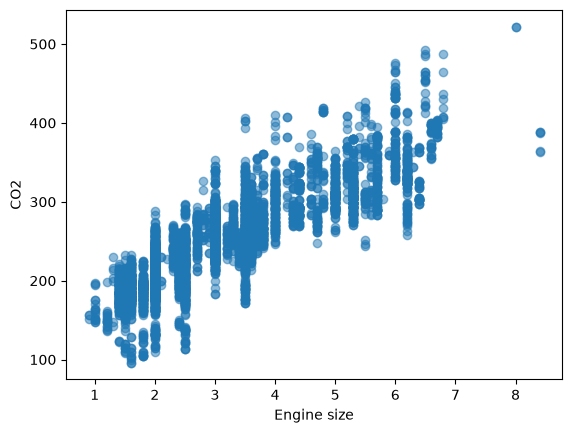

In [16]:
plt.scatter(df['engine_size'], df['co2'], alpha=0.5)
plt.xlabel('Engine size')
plt.ylabel('CO2')
plt.show()

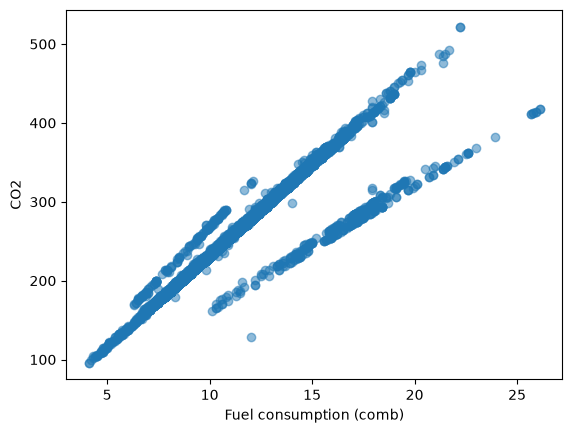

In [17]:
plt.scatter(df['fc_comb'], df['co2'], alpha=0.5)
plt.xlabel('Fuel consumption (comb)')
plt.ylabel('CO2')
plt.show()

In [18]:
# top 10 makes by average co2
df.groupby('make')['co2'].mean().sort_values(ascending=False).head(10)

make
BUGATTI         522.000000
LAMBORGHINI     402.270270
SRT             389.000000
ROLLS-ROYCE     388.750000
BENTLEY         367.914286
ASTON MARTIN    344.282051
MASERATI        318.134615
GMC             300.529412
RAM             294.180556
LAND ROVER      288.078947
Name: co2, dtype: float64

## Helper functions (numpy only)

Since scikit-learn is not allowed, the train/test split, scaling and evaluation metrics are written by hand.

In [21]:
def train_test_split(X, y, test_size=0.2, seed=42, stratify=False):
    rng = np.random.default_rng(seed)
    X = np.asarray(X, dtype=float); y = np.asarray(y)
    if stratify:
        test_idx = []
        for cls in np.unique(y):
            idx = rng.permutation(np.where(y == cls)[0])
            test_idx.extend(idx[:int(round(len(idx) * test_size))])
        test_idx = np.array(test_idx)
    else:
        idx = rng.permutation(len(y))
        test_idx = idx[:int(round(len(y) * test_size))]
    mask = np.zeros(len(y), dtype=bool); mask[test_idx] = True
    return X[~mask], X[mask], y[~mask], y[mask]

def standardize(X_train, X_test):
    mean, std = X_train.mean(axis=0), X_train.std(axis=0)
    std[std == 0] = 1
    return (X_train - mean) / std, (X_test - mean) / std

# regression metrics
def r2_score(y, p):  return 1 - np.sum((y - p)**2) / np.sum((y - y.mean())**2)
def mae(y, p):       return np.mean(np.abs(y - p))
def rmse(y, p):      return np.sqrt(np.mean((y - p)**2))

# classification metrics
def confusion_matrix(y, p):
    cm = np.zeros((2, 2), dtype=int)
    for a, b in zip(y, p):
        cm[int(a), int(b)] += 1
    return cm

def classification_metrics(y, p):
    cm = confusion_matrix(y, p)
    tn, fp, fn, tp = cm[0,0], cm[0,1], cm[1,0], cm[1,1]
    acc = (tp + tn) / cm.sum()
    prec = tp / (tp + fp) if tp + fp else 0
    rec = tp / (tp + fn) if tp + fn else 0
    f1 = 2 * prec * rec / (prec + rec) if prec + rec else 0
    return acc, prec, rec, f1

## 2. Linear Regression


In [ ]:
def lin_fit(X, y):
    Xb = np.c_[np.ones(len(X)), X]                 # add bias column
    w = np.linalg.lstsq(Xb, y, rcond=None)[0]      # normal equation solution
    return w[0], w[1:]                             # intercept, coefficients

def lin_pred(X, b, w):
    return np.asarray(X) @ w + b

### Simple linear regression (engine size vs CO2)

In [23]:
X_train, X_test, y_train, y_test = train_test_split(df[['engine_size']], df['co2'], test_size=0.2)

b, w = lin_fit(X_train, y_train)
print('Intercept:', b, ' Slope:', w)

Intercept: 132.72312933885374  Slope: [37.39079502]


In [24]:
y_pred = lin_pred(X_test, b, w)
print('R2  :', r2_score(y_test, y_pred))
print('MAE :', mae(y_test, y_pred))
print('RMSE:', rmse(y_test, y_pred))

R2  : 0.7188207467858021
MAE : 23.204483036338356
RMSE: 30.809644185130022


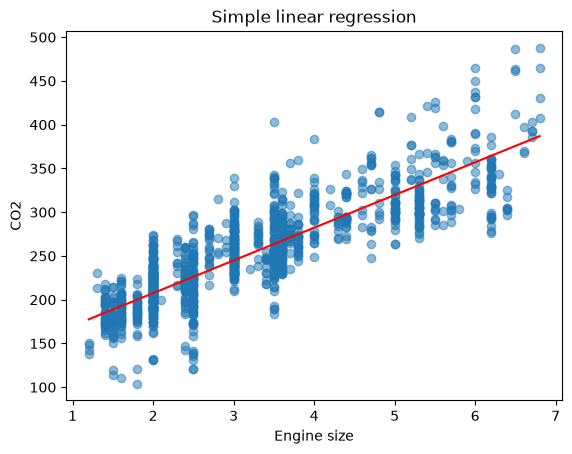

In [25]:
order = np.argsort(X_test[:, 0])
plt.scatter(X_test, y_test, alpha=0.5)
plt.plot(X_test[order], y_pred[order], color='red')
plt.xlabel('Engine size')
plt.ylabel('CO2')
plt.title('Simple linear regression')
plt.show()

### Multiple linear regression

In [ ]:
# numeric columns + fuel type (converted using get_dummies)
data = pd.get_dummies(df[['engine_size','cylinders','fc_comb','fuel_type','co2']], columns=['fuel_type'], drop_first=True).astype(float)
feature_names = data.drop('co2', axis=1).columns
X_train, X_test, y_train, y_test = train_test_split(data.drop('co2', axis=1), data['co2'], test_size=0.2)

b, w = lin_fit(X_train, y_train)
y_pred = lin_pred(X_test, b, w)

def lin_gd(X, y, lr=0.1, epochs=500):
    # gradient descent on standardized X; returns weights and loss history
    Xb = np.c_[np.ones(len(X)), X]
    w = np.zeros(Xb.shape[1]); history = []
    for _ in range(epochs):
        err = Xb @ w - y
        w -= lr * (2 / len(y)) * Xb.T @ err
        history.append(np.mean(err**2))
    return w, history

In [27]:
print('R2  :', r2_score(y_test, y_pred))
print('MAE :', mae(y_test, y_pred))
print('RMSE:', rmse(y_test, y_pred))

R2  : 0.9922248969336765
MAE : 3.1020317544600373
RMSE: 5.123280374488753


In [28]:
pd.DataFrame({'feature': feature_names, 'coefficient': w})

,feature,coefficient
0,engine_size,0.301130
1,cylinders,0.761933
2,fc_comb,22.141993
3,fuel_type_E,-142.673252
4,fuel_type_N,-111.032904
5,fuel_type_X,-30.115315
6,fuel_type_Z,-29.914142


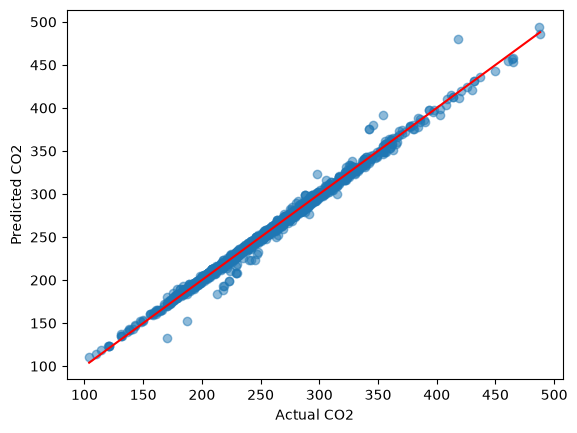

In [29]:
plt.scatter(y_test, y_pred, alpha=0.5)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color='red')
plt.xlabel('Actual CO2')
plt.ylabel('Predicted CO2')
plt.show()

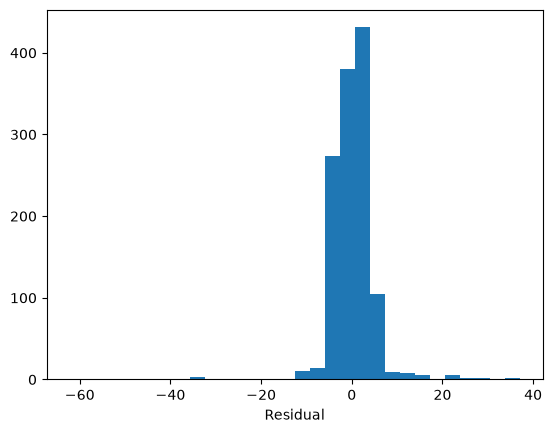

In [30]:
# residuals
residuals = y_test - y_pred
plt.hist(residuals, bins=30)
plt.xlabel('Residual')
plt.show()

### Gradient descent check


GD R2 : 0.9922290466999834
Normal equation R2: 0.9922248969336765


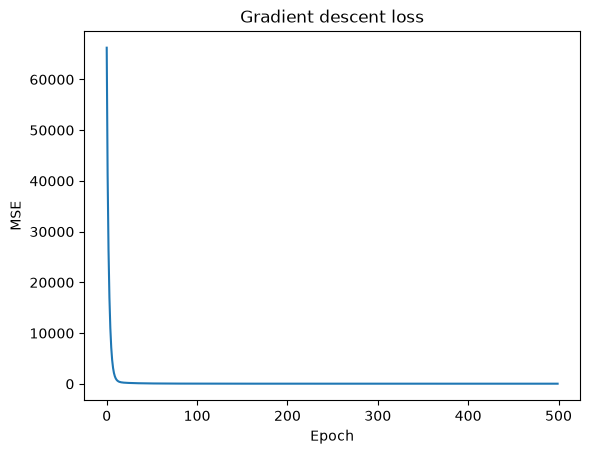

In [31]:
Xtr_s, Xte_s = standardize(X_train, X_test)
wg, hist = lin_gd(Xtr_s, y_train, lr=0.1, epochs=500)
y_pred_gd = np.c_[np.ones(len(Xte_s)), Xte_s] @ wg
print('GD R2 :', r2_score(y_test, y_pred_gd))
print('Normal equation R2:', r2_score(y_test, y_pred))

plt.plot(hist)
plt.xlabel('Epoch'); plt.ylabel('MSE'); plt.title('Gradient descent loss')
plt.show()

## 3. Logistic Regression


In [32]:
median = df['co2'].median()
df['high_co2'] = (df['co2'] > median).astype(int)
print('Median:', median)
df['high_co2'].value_counts()

Median: 246.0


high_co2
0    3200
1    3082
Name: count, dtype: int64

In [33]:
def sigmoid(z):
    return 1 / (1 + np.exp(-np.clip(z, -500, 500)))

def log_fit(X, y, lr=0.1, epochs=1000):
    n, m = X.shape
    w, b, loss = np.zeros(m), 0.0, []
    for _ in range(epochs):
        p = sigmoid(X @ w + b)
        w = w - lr * (X.T @ (p - y)) / n
        b = b - lr * np.mean(p - y)
        eps = 1e-12
        loss.append(-np.mean(y * np.log(p + eps) + (1 - y) * np.log(1 - p + eps)))
    return w, b, loss

def log_proba(X, w, b):
    return sigmoid(X @ w + b)

def log_pred(X, w, b, threshold=0.5):
    return (log_proba(X, w, b) >= threshold).astype(int)

In [34]:
data = pd.get_dummies(df[['engine_size','cylinders','fc_comb','fuel_type','high_co2']], columns=['fuel_type'], drop_first=True).astype(float)
feature_names = data.drop('high_co2', axis=1).columns
X_train, X_test, y_train, y_test = train_test_split(data.drop('high_co2', axis=1), data['high_co2'], test_size=0.2, stratify=True)

# scaling so gradient descent converges properly
X_train_s, X_test_s = standardize(X_train, X_test)

w, b, loss = log_fit(X_train_s, y_train, lr=0.1, epochs=1000)
y_pred = log_pred(X_test_s, w, b)

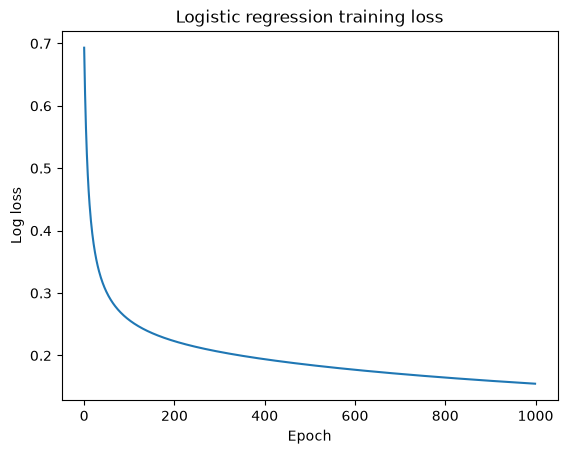

In [35]:
plt.plot(loss)
plt.xlabel('Epoch'); plt.ylabel('Log loss'); plt.title('Logistic regression training loss')
plt.show()

In [36]:
acc, prec, rec, f1 = classification_metrics(y_test, y_pred)
print('Accuracy :', round(acc, 4))
print('Precision:', round(prec, 4))
print('Recall   :', round(rec, 4))
print('F1 score :', round(f1, 4))

Accuracy : 0.9228
Precision: 0.9126
Recall   : 0.9318
F1 score : 0.9221


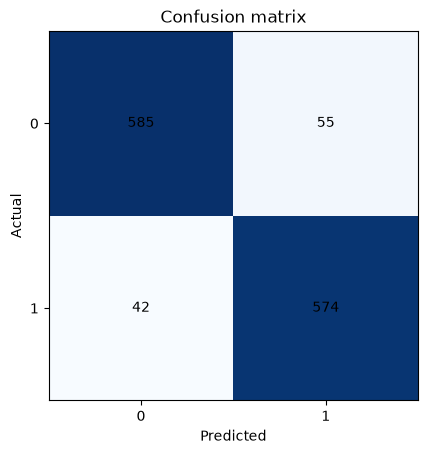

In [37]:
cm = confusion_matrix(y_test, y_pred)
plt.imshow(cm, cmap='Blues')
for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i, j], ha='center', va='center')
plt.xticks([0,1]); plt.yticks([0,1])
plt.xlabel('Predicted'); plt.ylabel('Actual')
plt.title('Confusion matrix')
plt.show()

In [38]:
# coefficients (on standardized features) show which features push towards 'high emitter'
pd.DataFrame({'feature': feature_names, 'weight': w}).sort_values('weight', ascending=False)

,feature,weight
2,fc_comb,3.602027
0,engine_size,1.103734
1,cylinders,0.898938
4,fuel_type_N,-0.107737
5,fuel_type_X,-0.126726
6,fuel_type_Z,-0.330280
3,fuel_type_E,-1.196794
